# Maximum Likelihood Training of Score-Based Diffusion Models（ScoreFlow, 2021）

这个 notebook 用可解析的二维高斯混合分布，复现 ScoreFlow 的核心观点：常用的 denoising score matching（DSM）训练目标偏向样本质量，而适当的 likelihood weighting 能建立与最大似然的联系；对时间变量做 importance sampling 可以显著降低加权目标的训练方差。

我们训练并比较三个模型：

| 模型 | 时间采样 | 噪声 MSE 权重 |
|---|---|---|
| DSM | $t\sim\mathcal U(\epsilon,1)$ | $1$ |
| ML | $t\sim\mathcal U(\epsilon,1)$ | $\beta(t)/\sigma^2(t)$ |
| ML + IS | $t\sim\rho(t)\propto\beta(t)/\sigma^2(t)$ | 积分归一化常数 |

实验会分别检查训练稳定性、解析 Score 误差、Probability Flow ODE 采样和连续密度 NLL。

## 1. 二维数据与 VP-SDE

数据分布为

$$
p_0(x)=\tfrac12\mathcal N((-3,-3),0.6^2I)
+\tfrac12\mathcal N((3,3),0.6^2I).
$$

使用 VP-SDE：

$$
dx=-\tfrac12\beta(t)x\,dt+\sqrt{\beta(t)}\,dW_t,
\qquad \beta(t)=0.1+19.9t.
$$

其闭式扰动核为 $x_t=\alpha(t)x_0+\sigma(t)\epsilon$，其中

$$
B(t)=\int_0^t\beta(s)ds,\quad
\alpha(t)=e^{-B(t)/2},\quad
\sigma^2(t)=1-e^{-B(t)}.
$$

In [1]:
from pathlib import Path
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

OUTPUT_DIR = Path("scoreflow_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

DIM = 2
MEANS = torch.tensor([[-3.0, -3.0], [3.0, 3.0]], device=DEVICE)
WEIGHTS = torch.tensor([0.5, 0.5], device=DEVICE)
DATA_STD = 0.6

BETA_MIN, BETA_MAX = 0.1, 20.0
T_MIN, T_MAX = 1e-3, 1.0
TRAIN_STEPS = 4_000
BATCH_SIZE = 1_024
N_SAMPLES = 2_500
ODE_STEPS = 500

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

PyTorch: 2.5.1
Device: cuda
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/scoreflow_outputs


In [2]:
def sample_data(n):
    labels = torch.multinomial(WEIGHTS, n, replacement=True)
    return MEANS[labels] + DATA_STD * torch.randn(n, DIM, device=DEVICE)


def beta(t):
    return BETA_MIN + (BETA_MAX-BETA_MIN)*t


def integrated_beta(t):
    return BETA_MIN*t + 0.5*(BETA_MAX-BETA_MIN)*t.square()


def sigma2(t):
    return -torch.expm1(-integrated_beta(t))


def alpha_sigma(t):
    b = integrated_beta(t)
    return torch.exp(-0.5*b), torch.sqrt((-torch.expm1(-b)).clamp_min(1e-12))


def perturb(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    alpha, sigma = alpha_sigma(t)
    return alpha*x0 + sigma*noise, noise


terminal_alpha, terminal_sigma = alpha_sigma(torch.tensor(1.0, device=DEVICE))
print(f"alpha(1)={terminal_alpha.item():.6f}, sigma(1)={terminal_sigma.item():.6f}")

alpha(1)=0.006572, sigma(1)=0.999978


## 2. 为什么 likelihood weighting 会在小时间变大？

ScoreFlow 的 likelihood-weighted目标使用 $\lambda(t)=g^2(t)=\beta(t)$：

$$
\int_\epsilon^1 \beta(t)\,
\mathbb E\|s_\theta(x_t,t)-\nabla_{x_t}\log p_{0t}(x_t\mid x_0)\|^2dt.
$$

网络采用噪声参数化 $s_\theta=-\hat\epsilon_\theta/\sigma(t)$，所以忽略与参数无关的常数后，目标变为

$$
\int_\epsilon^1
\underbrace{\frac{\beta(t)}{\sigma^2(t)}}_{w(t)}
\mathbb E\|\hat\epsilon_\theta-\epsilon\|^2dt.
$$

当 $t\to0$ 时，$w(t)\approx1/t$。均匀采样时间会偶尔抽到权重极大的样本，导致梯度方差很高。

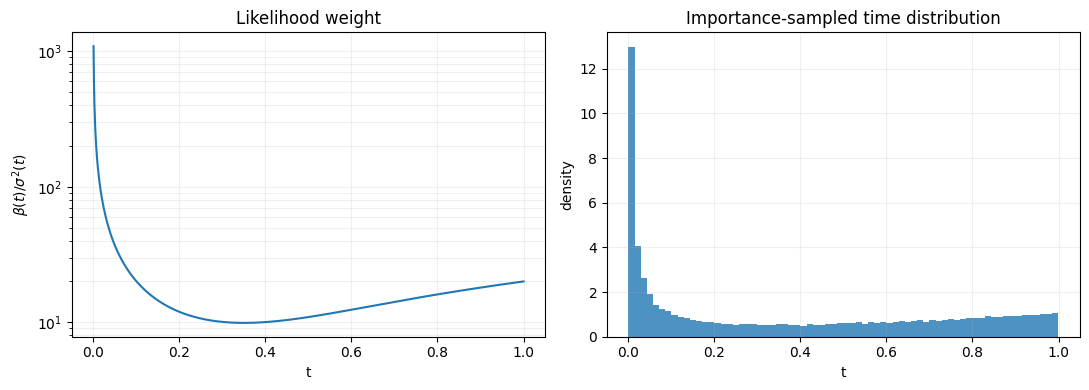

Importance integral normalizer Z=19.165386


In [3]:
def likelihood_weight(t):
    return beta(t)/sigma2(t)


def importance_times(n):
    # rho(t) ∝ beta(t)/(1-exp(-B(t))) 的精确逆 CDF。
    lo = torch.tensor(T_MIN, device=DEVICE)
    hi = torch.tensor(T_MAX, device=DEVICE)

    def antiderivative(t):
        b = integrated_beta(t)
        return b + torch.log(-torch.expm1(-b))  # log(exp(B)-1)，稳定写法

    f_lo, f_hi = antiderivative(lo), antiderivative(hi)
    u = torch.rand(n, 1, device=DEVICE)
    z = f_lo + u*(f_hi-f_lo)
    b = torch.nn.functional.softplus(z)  # z=log(exp(B)-1) 的逆变换
    delta = BETA_MAX-BETA_MIN
    t = (2*b)/(BETA_MIN+torch.sqrt(BETA_MIN**2+2*delta*b))
    return t, f_hi-f_lo


t_grid = torch.linspace(T_MIN, T_MAX, 1_000, device=DEVICE)[:, None]
is_times, normalizer = importance_times(50_000)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].semilogy(t_grid.cpu(), likelihood_weight(t_grid).cpu())
axes[0].set(xlabel="t", ylabel=r"$\beta(t)/\sigma^2(t)$", title="Likelihood weight")
axes[0].grid(alpha=0.2, which="both")
axes[1].hist(is_times.cpu().numpy().ravel(), bins=70, density=True, alpha=0.8)
axes[1].set(xlabel="t", ylabel="density", title="Importance-sampled time distribution")
axes[1].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_likelihood_weight_and_time_sampling.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"Importance integral normalizer Z={normalizer.item():.6f}")

## 3. 共享的连续时间网络

三个实验使用完全相同的网络结构。网络输出噪声预测 $\hat\epsilon_\theta$，Score 通过 $-\hat\epsilon_\theta/\sigma(t)$ 得到。每个模型训练前重置相同随机种子，使差异主要来自目标和时间采样策略。

In [4]:
class NoiseNet(nn.Module):
    def __init__(self, hidden=128, time_dim=32):
        super().__init__()
        self.time_dim = time_dim
        self.net = nn.Sequential(
            nn.Linear(DIM+time_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, DIM),
        )

    def time_embedding(self, t):
        frequencies = torch.exp(
            torch.linspace(math.log(1.0), math.log(1_000.0), self.time_dim//2, device=t.device)
        )
        angles = 2*math.pi*t*frequencies[None, :]
        return torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)

    def forward(self, x, t):
        if t.ndim == 0:
            t = t.expand(len(x), 1)
        elif t.ndim == 1:
            t = t[:, None]
        return self.net(torch.cat([x/4.0, self.time_embedding(t)], dim=1))

    def score(self, x, t):
        if t.ndim == 0:
            t = t.expand(len(x), 1)
        elif t.ndim == 1:
            t = t[:, None]
        return -self.forward(x, t)/torch.sqrt(sigma2(t))


probe_model = NoiseNet().to(DEVICE)
print(probe_model)
print(f"Trainable parameters per model: {sum(p.numel() for p in probe_model.parameters()):,}")
del probe_model

NoiseNet(
  (net): Sequential(
    (0): Linear(in_features=34, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters per model: 37,762


## 4. 三种训练目标

`ML` 直接在均匀时间样本上乘 $w(t)$。`ML + IS` 从 $\rho(t)=w(t)/Z$ 抽样后只需计算 $Z\cdot\mathrm{MSE}$：

$$
\int w(t)L(t)dt
=Z\,\mathbb E_{t\sim\rho}[L(t)].
$$

两者期望相同，但 Monte Carlo 方差不同。梯度裁剪用于限制直接 ML 偶遇极小 $t$ 时的异常大梯度。

In [5]:
def train_model(mode, seed=SEED):
    torch.manual_seed(seed)
    model = NoiseNet().to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history, grad_history = [], []
    model.train()

    for step in range(1, TRAIN_STEPS+1):
        x0 = sample_data(BATCH_SIZE)
        if mode == "ml_is":
            t, z = importance_times(BATCH_SIZE)
        else:
            t = T_MIN+(T_MAX-T_MIN)*torch.rand(BATCH_SIZE, 1, device=DEVICE)

        xt, noise = perturb(x0, t)
        mse = (model(xt, t)-noise).square().sum(dim=1, keepdim=True)
        if mode == "dsm":
            loss = mse.mean()
        elif mode == "ml":
            loss = (likelihood_weight(t)*mse).mean()
        else:
            loss = (z*mse).mean()

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        history.append(loss.item())
        grad_history.append(float(grad_norm))

        if step == 1 or step % 800 == 0:
            print(f"{mode:5s} step {step:4d}/{TRAIN_STEPS} | loss={np.mean(history[-200:]):.5f}")
    return model.eval(), history, grad_history


models, histories, grad_histories = {}, {}, {}
training_started = time.perf_counter()
for mode in ["dsm", "ml", "ml_is"]:
    models[mode], histories[mode], grad_histories[mode] = train_model(mode)
    torch.save(models[mode].state_dict(), OUTPUT_DIR/f"scoreflow_{mode}_state_dict.pt")
print(f"All three models trained in {time.perf_counter()-training_started:.1f} s")

dsm   step    1/4000 | loss=2.09481


dsm   step  800/4000 | loss=0.54253


dsm   step 1600/4000 | loss=0.52673


dsm   step 2400/4000 | loss=0.52482


dsm   step 3200/4000 | loss=0.51883


...

ml_is step  800/4000 | loss=18.09102


ml_is step 1600/4000 | loss=17.73155


ml_is step 2400/4000 | loss=17.70515


ml_is step 3200/4000 | loss=17.70154


ml_is step 4000/4000 | loss=17.80097
All three models trained in 38.3 s


## 5. 比较训练稳定性

三种 loss 的绝对尺度不同，不能直接用数值大小判断模型优劣。左图把各自的平滑 loss 除以初始平滑值，比较相对收敛；右图比较未裁剪梯度范数。直接 ML 的尖峰反映均匀时间采样下高权重样本造成的方差，importance sampling 应使曲线更稳定。

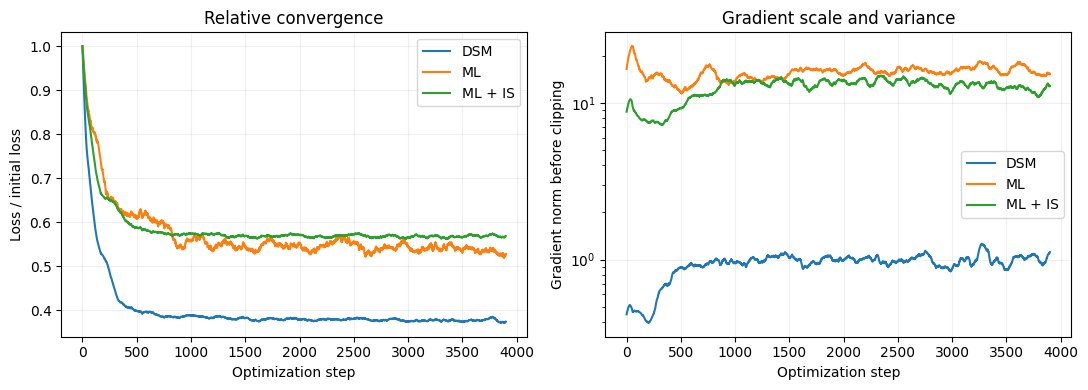

In [6]:
window = 100
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
labels = {"dsm": "DSM", "ml": "ML", "ml_is": "ML + IS"}
for mode in models:
    smooth = np.convolve(histories[mode], np.ones(window)/window, mode="valid")
    axes[0].plot(smooth/smooth[0], label=labels[mode])
    grad_smooth = np.convolve(grad_histories[mode], np.ones(window)/window, mode="valid")
    axes[1].plot(grad_smooth, label=labels[mode])
axes[0].set(xlabel="Optimization step", ylabel="Loss / initial loss", title="Relative convergence")
axes[1].set(xlabel="Optimization step", ylabel="Gradient norm before clipping", title="Gradient scale and variance")
axes[1].set_yscale("log")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_training_stability.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. 解析 Score 与分时刻误差

因为数据是高斯混合，$p_t$ 仍是高斯混合，可以解析计算 $\nabla_x\log p_t(x)$。下面报告 scaled Score MSE：

$$
\sigma^2(t)\,\mathbb E\|s_\theta(x_t,t)-s^*(x_t,t)\|^2,
$$

它等价于噪声参数化误差的尺度，便于跨时刻比较。

Scaled score MSE
      t          DSM           ML      ML + IS
  0.005     0.006898     0.001757     0.000476
  0.010     0.003803     0.002170     0.000905
  0.030     0.004585     0.005928     0.002543
  0.100     0.001576     0.003580     0.002017
  0.300     0.007975     0.017543     0.010253
  0.600     0.001446     0.001732     0.001071
  1.000     0.007333     0.012720     0.031930


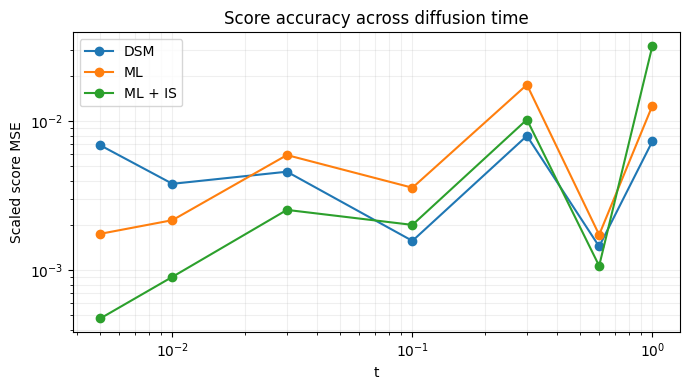

In [7]:
def exact_score(x, t):
    if t.ndim == 0:
        t = t.expand(len(x), 1)
    elif t.ndim == 1:
        t = t[:, None]
    alpha, sigma = alpha_sigma(t)
    centers = alpha[:, None, :]*MEANS[None, :, :]
    variance = (alpha.square()*DATA_STD**2+sigma.square())[:, None, :]
    delta = x[:, None, :]-centers
    logits = torch.log(WEIGHTS)[None, :]-delta.square().sum(-1)/(2*variance.squeeze(-1))
    responsibility = torch.softmax(logits, dim=1)
    return (responsibility[:, :, None]*(-delta/variance)).sum(dim=1)


@torch.no_grad()
def score_error_table(n=10_000):
    times = [0.005, 0.01, 0.03, 0.1, 0.3, 0.6, 1.0]
    result = {mode: [] for mode in models}
    for t_value in times:
        t = torch.full((n, 1), t_value, device=DEVICE)
        xt, _ = perturb(sample_data(n), t)
        target = exact_score(xt, t)
        for mode, model in models.items():
            error = sigma2(t)*(model.score(xt, t)-target).square()
            result[mode].append(error.mean().item())
    return np.asarray(times), result


eval_times, score_errors = score_error_table()
print("Scaled score MSE")
print(f"{'t':>7} {'DSM':>12} {'ML':>12} {'ML + IS':>12}")
for i, t_value in enumerate(eval_times):
    print(f"{t_value:7.3f} {score_errors['dsm'][i]:12.6f} {score_errors['ml'][i]:12.6f} {score_errors['ml_is'][i]:12.6f}")

plt.figure(figsize=(7, 4))
for mode in models:
    plt.loglog(eval_times, score_errors[mode], "o-", label=labels[mode])
plt.xlabel("t")
plt.ylabel("Scaled score MSE")
plt.title("Score accuracy across diffusion time")
plt.grid(alpha=0.2, which="both")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_score_error_by_time.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Probability Flow ODE 采样

VP-SDE 对应的概率流 ODE 为

$$
\frac{dx}{dt}=-\frac12\beta(t)[x+s_\theta(x,t)].
$$

生成时从 $t=1$ 向 $t=\epsilon$ 积分。使用解析 Score 的 Oracle ODE 用来检查 Euler 离散误差；三个学习模型使用相同初始噪声，便于比较。

In [8]:
@torch.no_grad()
def sample_ode(score_fn, initial_noise, nsteps=ODE_STEPS):
    x = initial_noise.clone()
    grid = torch.linspace(T_MAX, T_MIN, nsteps+1, device=DEVICE)
    for i in range(nsteps):
        t = grid[i].expand(len(x), 1)
        h = grid[i]-grid[i+1]
        score = score_fn(x, t)
        x = x+0.5*h*beta(t)*(x+score)
    return x.cpu().numpy()


initial_noise = torch.randn(N_SAMPLES, DIM, device=DEVICE)
sampling_started = time.perf_counter()
generated = {labels[mode]: sample_ode(model.score, initial_noise) for mode, model in models.items()}
generated["Oracle score"] = sample_ode(exact_score, initial_noise)
with torch.no_grad():
    real = sample_data(N_SAMPLES).cpu().numpy()
print(f"Four ODE samplers finished in {time.perf_counter()-sampling_started:.1f} s")

Four ODE samplers finished in 1.2 s


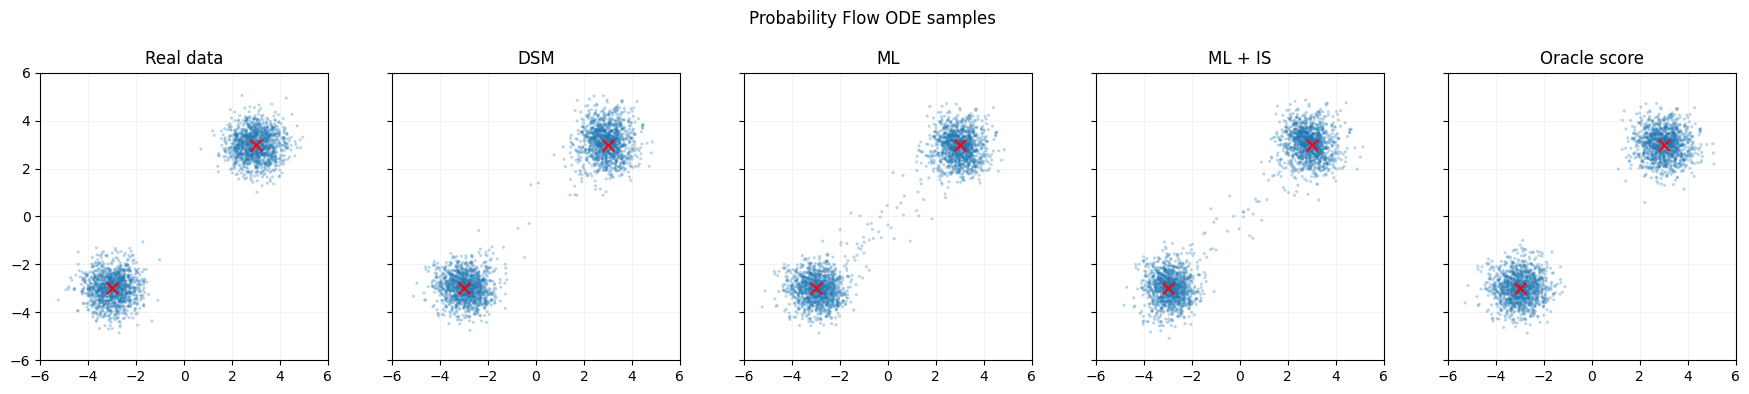

distribution     weights            mean error   avg std
Real data        [0.486 0.514]          0.0181    0.5973
DSM              [0.505 0.495]          0.0946    0.6117
ML               [0.502 0.498]          0.1138    0.6456
ML + IS          [0.488 0.512]          0.1275    0.6350
Oracle score     [0.506 0.494]          0.0131    0.6030


In [9]:
def scatter(ax, points, title):
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.3, edgecolors="none")
    ax.scatter(MEANS[:, 0].cpu(), MEANS[:, 1].cpu(), c="red", marker="x", s=70)
    ax.set(title=title, xlim=(-6, 6), ylim=(-6, 6))
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)


fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharex=True, sharey=True)
scatter(axes[0], real, "Real data")
for ax, (name, points) in zip(axes[1:], generated.items()):
    scatter(ax, points, name)
fig.suptitle("Probability Flow ODE samples", y=1.03)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_probability_flow_samples.png", dpi=160, bbox_inches="tight")
plt.show()


def distribution_summary(points):
    points_t = torch.as_tensor(points, dtype=torch.float32, device=DEVICE)
    cluster = torch.cdist(points_t, MEANS).argmin(dim=1)
    weights = torch.bincount(cluster, minlength=2).float()/len(points_t)
    means = torch.stack([points_t[cluster == i].mean(0) for i in range(2)])
    stds = torch.stack([points_t[cluster == i].std(0) for i in range(2)])
    mean_error = torch.linalg.vector_norm(means-MEANS, dim=1).mean()
    return weights.cpu().numpy(), mean_error.item(), stds.mean().item()


print(f"{'distribution':<16} {'weights':<17} {'mean error':>11} {'avg std':>9}")
for name, points in [("Real data", real), *generated.items()]:
    weights, mean_error, avg_std = distribution_summary(points)
    print(f"{name:<16} {str(np.round(weights,3)):<17} {mean_error:11.4f} {avg_std:9.4f}")

## 8. Probability Flow ODE 的连续密度

对 ODE $dx/dt=v_\theta(x,t)$，瞬时变量替换公式为

$$
\frac{d\log p_t(x_t)}{dt}=-\nabla\cdot v_\theta(x_t,t).
$$

从 $T_{\min}$ 向 1 同时积分状态和散度，并在终点使用标准高斯密度，可得到

$$
\log p_{T_{\min}}(x)=\log p_1(x_1)+
\int_{T_{\min}}^1\nabla\cdot v_\theta(x_t,t)dt.
$$

二维情况下可以用 autograd 精确计算散度。这里报告的是加噪到 $T_{\min}=10^{-3}$ 后的 NLL；同时计算该边缘分布的解析 NLL 和 Oracle ODE NLL，作为数值基准。

NLL evaluation finished in 1.8 s
NLL at T_MIN (nats per 2D sample)
Exact marginal  : 2.48558
DSM             : 2.51558
ML              : 2.53334
ML + IS         : 2.58109
Oracle ODE      : 2.47684


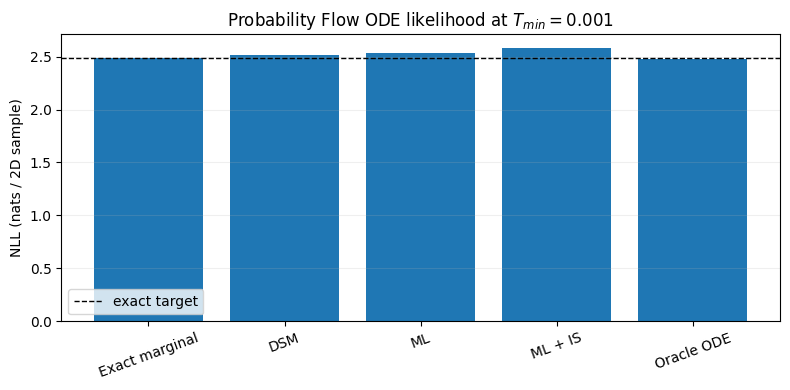

In [10]:
def ode_velocity(score_fn, x, t):
    return -0.5*beta(t)*(x+score_fn(x, t))


def velocity_and_divergence(score_fn, x, t):
    with torch.enable_grad():
        x = x.detach().requires_grad_(True)
        velocity = ode_velocity(score_fn, x, t)
        divergence = torch.zeros(len(x), device=x.device)
        for dim in range(DIM):
            grad = torch.autograd.grad(
                velocity[:, dim].sum(), x, retain_graph=(dim < DIM-1)
            )[0]
            divergence = divergence+grad[:, dim]
    return velocity.detach(), divergence.detach()


def estimate_ode_nll(score_fn, data, nsteps=200):
    x = data.clone()
    divergence_integral = torch.zeros(len(x), device=DEVICE)
    grid = torch.linspace(T_MIN, T_MAX, nsteps+1, device=DEVICE)
    for i in range(nsteps):
        t = grid[i].expand(len(x), 1)
        h = grid[i+1]-grid[i]
        velocity, divergence = velocity_and_divergence(score_fn, x, t)
        x = x+h*velocity
        divergence_integral = divergence_integral+h*divergence
    log_prior = -0.5*(x.square().sum(-1)+DIM*math.log(2*math.pi))
    return (-log_prior-divergence_integral).mean().item()


def exact_marginal_nll(data, t_value):
    t = torch.full((len(data), 1), t_value, device=DEVICE)
    alpha, sigma = alpha_sigma(t)
    variance = alpha.square()*DATA_STD**2+sigma.square()
    centers = alpha[:, None, :]*MEANS[None, :, :]
    delta = data[:, None, :]-centers
    log_components = (
        torch.log(WEIGHTS)[None, :]
        -0.5*delta.square().sum(-1)/variance
        -math.log(2*math.pi)-torch.log(variance)
    )
    return (-torch.logsumexp(log_components, dim=1)).mean().item()


NLL_SAMPLES = 128
data0 = sample_data(NLL_SAMPLES)
tmin_batch = torch.full((NLL_SAMPLES, 1), T_MIN, device=DEVICE)
data_tmin, _ = perturb(data0, tmin_batch)

nll_results = {"Exact marginal": exact_marginal_nll(data_tmin, T_MIN)}
nll_started = time.perf_counter()
for mode, model in models.items():
    nll_results[labels[mode]] = estimate_ode_nll(model.score, data_tmin)
nll_results["Oracle ODE"] = estimate_ode_nll(exact_score, data_tmin)

print(f"NLL evaluation finished in {time.perf_counter()-nll_started:.1f} s")
print("NLL at T_MIN (nats per 2D sample)")
for name, value in nll_results.items():
    print(f"{name:<16}: {value:.5f}")

plt.figure(figsize=(8, 4))
names = list(nll_results)
values = [nll_results[name] for name in names]
bars = plt.bar(names, values)
plt.axhline(nll_results["Exact marginal"], color="black", ls="--", lw=1, label="exact target")
plt.ylabel("NLL (nats / 2D sample)")
plt.title(f"Probability Flow ODE likelihood at $T_{{min}}={T_MIN}$")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.2)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_ode_likelihood.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. 如何解读结果

- **训练 loss 不能横向直接比较**：DSM、ML 与 ML + IS 的积分测度和数值尺度不同。
- **ML 与 ML + IS 优化相同的期望目标**：差别来自 Monte Carlo 时间采样方差；有限训练下结果不会完全一致。
- **样本图与 NLL 衡量不同方面**：DSM 常能得到很好的感知样本，但 likelihood weighting 更直接对应模型似然。
- **ODE NLL 是模型与数值求解器的联合结果**：Oracle ODE 与解析边缘 NLL 的差距反映有限 Euler 步数和终端近似误差。
- **这里报告 $T_{\min}$ 的连续密度**：它非常接近原数据时刻，但不是离散图像任务中的 bits/dim，也没有加入 dequantization。

### 代码与公式对应

| 代码 | 数学对象 |
|---|---|
| `likelihood_weight(t)` | $g^2(t)/\sigma^2(t)=\beta(t)/\sigma^2(t)$ |
| `importance_times()` | $\rho(t)\propto\beta(t)/\sigma^2(t)$ 的逆 CDF |
| `NoiseNet.score()` | $s_\theta=-\hat\epsilon_\theta/\sigma(t)$ |
| `sample_ode()` | 反向 Probability Flow ODE |
| `velocity_and_divergence()` | $\nabla\cdot v_\theta$ |
| `estimate_ode_nll()` | 瞬时变量替换公式计算连续密度 |
| `exact_score()` | 解析边缘 Score，用于独立验收 |